<a href="https://colab.research.google.com/github/jjyjung/ai/blob/gh-pages/yolo/yolo26_task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Ultralytics의 패지키 업데이트**

In [1]:
# 1. Ultralytics 패키지 설치
!pip install ultralytics --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 11.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


## **객체 탐지(Detection)**

In [90]:
# 2. 필요한 라이브러리 임포트
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt  # 이미지를 표시할 때 사용
from google.colab.patches import cv2_imshow  # Colab에서 OpenCV 이미지 표시 지원
import os

# 3. YOLO 최신 모델 로드
model = YOLO("yolo26n.pt")  # 사전 학습된 COCO 모델 (n: Nano, m: Medium, l: Large 등)

# 4. 이미지 처리 및 결과 표시 함수
def process_image(image_path, conf=0.25, iou=0.5):
    # 이미지 로드
    img = cv2.imread(image_path)
    if img is None:
        print(f"Error: Unable to load image from {image_path}")
        return

    # YOLO 모델로 추론
    # results = model(img)    # 조정 없음
    results = model.predict(img, conf=conf, iou=iou,  # conf, iou 임계값 조정 가능
                            agnostic_nms=True)   # 디폴트값인 agnostic_nms=False이면 같은 클래스 객체끼리만 NMS 적용
    print(results)

    # 결과를 이미지에 시각화
    annotated_frame = results[0].plot()

    # Colab에서 이미지 표시
    cv2_imshow(annotated_frame)
    # # PyCharm 버전
    # cv2.imshow("YOLO Detection", img); cv2.waitKey(0); cv2.destroyAllWindows()

Saving cat.jpg to cat (4).jpg
Processing cat (4).jpg...

0: 640x640 1 person, 1 cat, 1 potted plant, 8.9ms
Speed: 2.6ms preprocess, 8.9ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
colors: None
depth: None
keypoints: None
masks: None
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'f

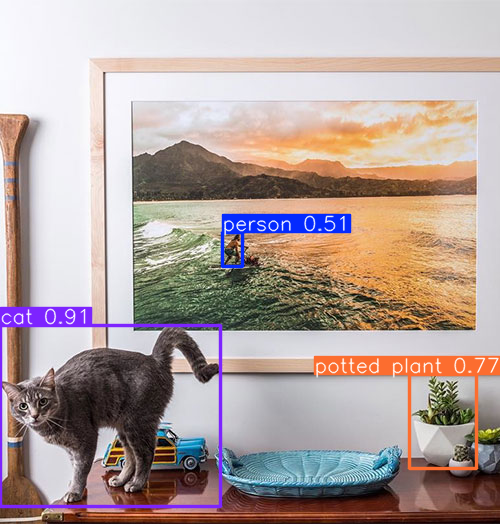

In [53]:
# 5. 예제 이미지 업로드 및 처리
from google.colab import files

uploaded = files.upload()  # 로컬에서 이미지 파일 업로드
for filename in uploaded.keys():
    print(f"Processing {filename}...")
    process_image(filename)

# PyCharm 버전
# process_image("./img/livingroom.jpg")

# 결과 확인!!!
# 1 person, 1 cat, 1 potted plant


0: 640x640 3 persons, 1 car, 2 trucks, 1 cat, 5 surfboards, 4 bowls, 3 potted plants, 1 dining table, 2 books, 3 vases, 11.7ms
Speed: 3.0ms preprocess, 11.7ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)
[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
colors: None
depth: None
keypoints: None
masks: None
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine gla

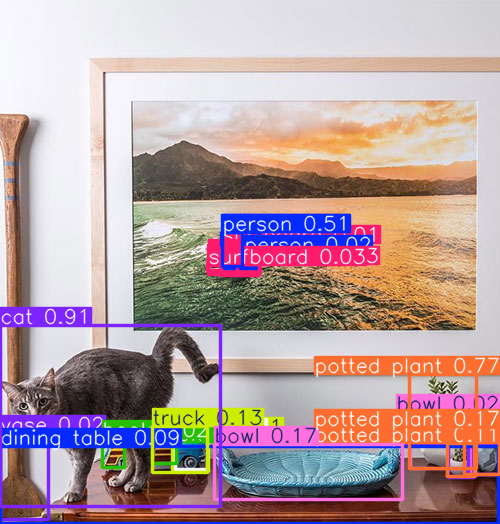

In [66]:
process_image(filename, conf=0.01)


0: 640x640 2 persons, 1 car, 1 truck, 1 cat, 1 surfboard, 2 bowls, 1 potted plant, 1 dining table, 2 books, 2 vases, 10.7ms
Speed: 2.9ms preprocess, 10.7ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
colors: None
depth: None
keypoints: None
masks: None
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass'

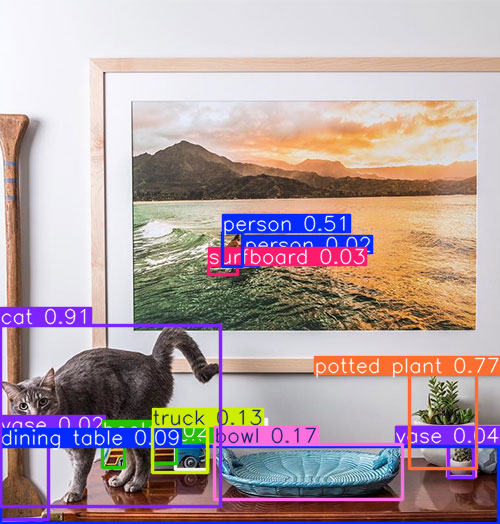

In [68]:
process_image(filename, conf=0.01, iou=0.01)

Saving livingroom.jpg to livingroom (3).jpg
Processing livingroom (3).jpg...

0: 448x640 1 wine glass, 2 chairs, 2 potted plants, 1 dining table, 1 vase, 12.4ms
Speed: 2.0ms preprocess, 12.4ms inference, 1.4ms postprocess per image at shape (1, 3, 448, 640)
[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
colors: None
depth: None
keypoints: None
masks: None
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis rac

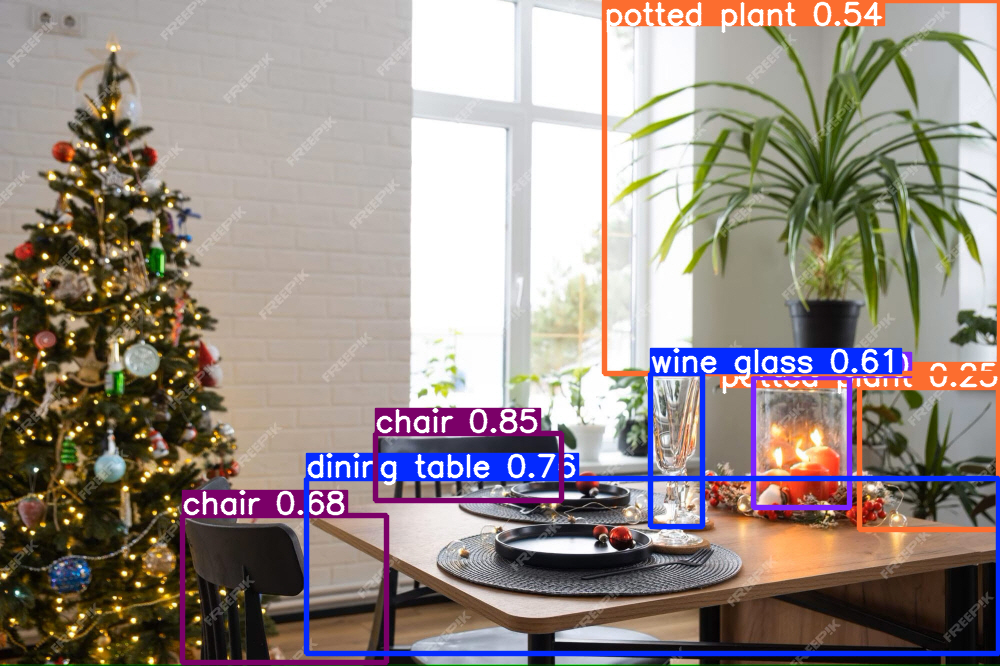

In [69]:
uploaded = files.upload()  # 로컬에서 이미지 파일 업로드
for filename in uploaded.keys():
    print(f"Processing {filename}...")
    process_image(filename)


0: 448x640 1 wine glass, 2 chairs, 7 potted plants, 1 dining table, 2 vases, 11.0ms
Speed: 2.6ms preprocess, 11.0ms inference, 1.5ms postprocess per image at shape (1, 3, 448, 640)
[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
colors: None
depth: None
keypoints: None
masks: None
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44

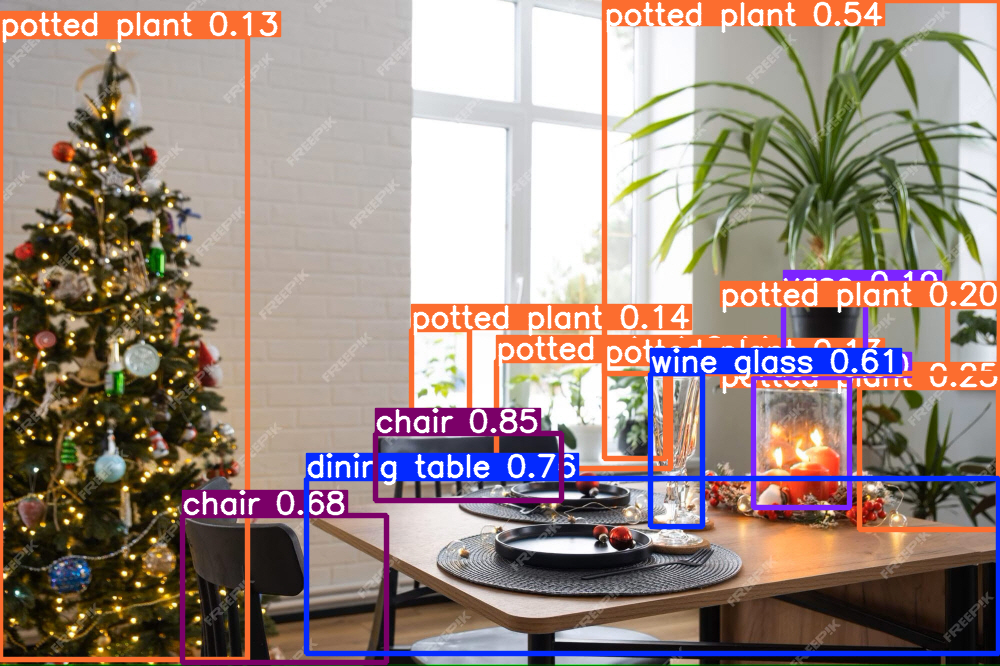

In [72]:
process_image(filename, conf=0.1)


0: 448x640 1 wine glass, 2 chairs, 3 potted plants, 1 vase, 11.3ms
Speed: 2.5ms preprocess, 11.3ms inference, 1.5ms postprocess per image at shape (1, 3, 448, 640)
[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
colors: None
depth: None
keypoints: None
masks: None
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'b

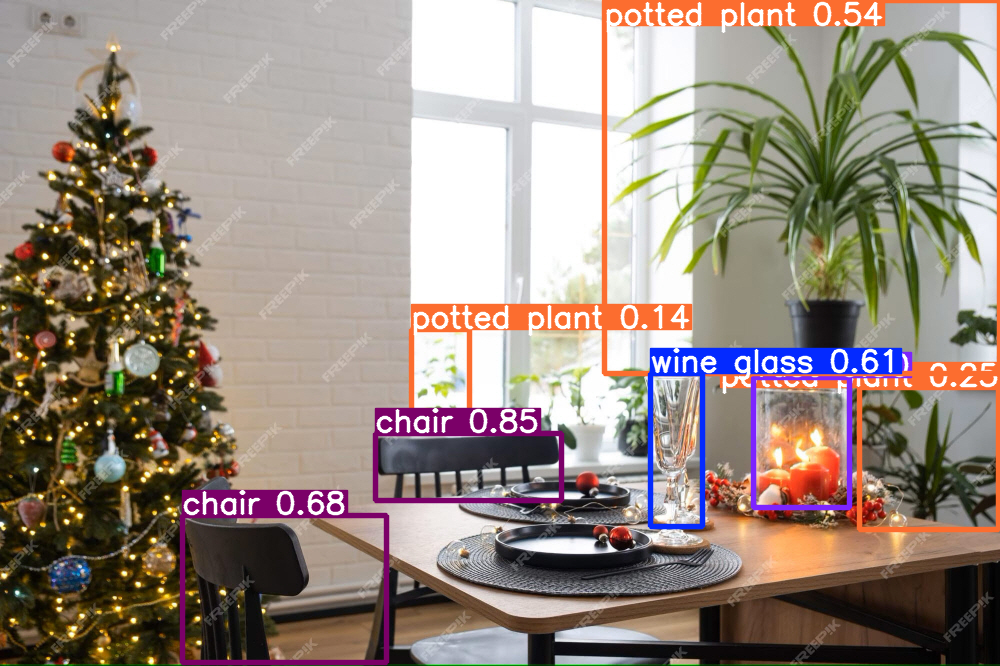

In [96]:
process_image(filename, conf=0.1, iou=0.01)


0: 448x640 1 wine glass, 2 chairs, 1 potted plant, 1 dining table, 9.8ms
Speed: 2.5ms preprocess, 9.8ms inference, 1.9ms postprocess per image at shape (1, 3, 448, 640)
[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
colors: None
depth: None
keypoints: None
masks: None
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 4

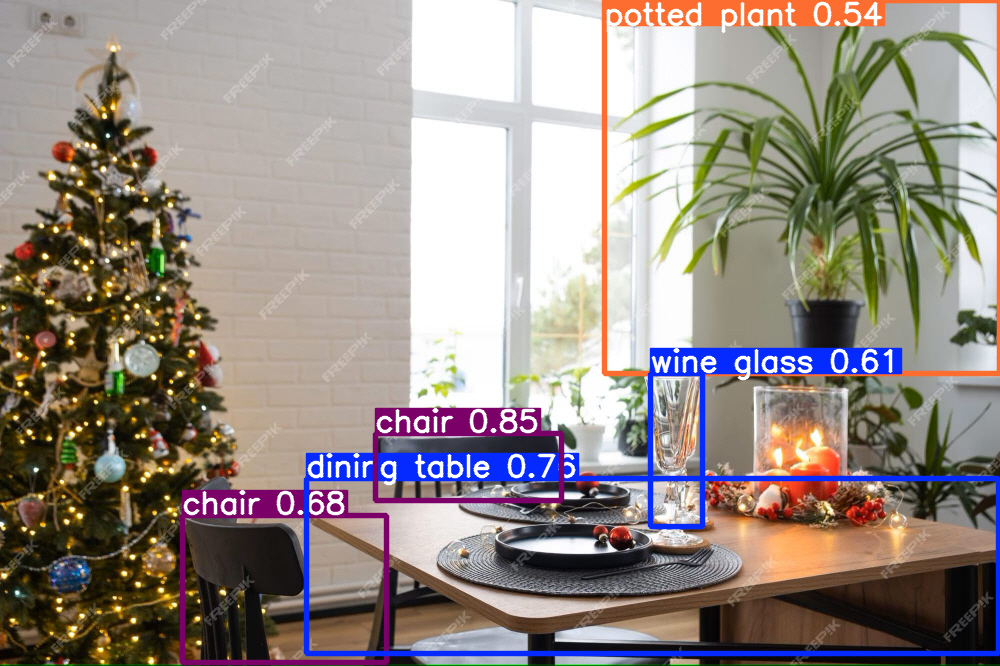

In [99]:
process_image(filename, 0.4, 0.1)

## **객체 탐지(Detection) - 결과 접근**

Saving livingroom.jpg to livingroom (4).jpg
Processing livingroom (4).jpg...

0: 448x640 1 wine glass, 2 chairs, 2 potted plants, 1 dining table, 1 vase, 10.3ms
Speed: 2.3ms preprocess, 10.3ms inference, 1.4ms postprocess per image at shape (1, 3, 448, 640)


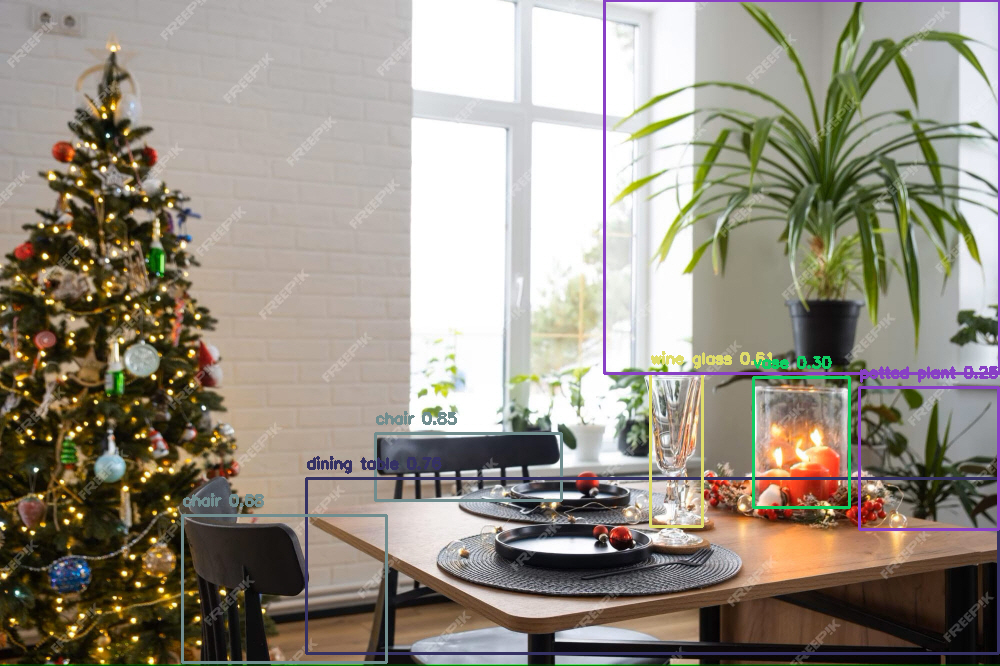

In [100]:
# 2. 필요한 라이브러리 임포트
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt  # 이미지를 표시할 때 사용
from google.colab.patches import cv2_imshow  # Colab에서 OpenCV 이미지 표시 지원
import os
import numpy as np

# 3. YOLO 최신 모델 로드
model = YOLO("yolo26n.pt")  # 사전 학습된 COCO 모델 (n: Nano, m: Medium, l: Large 등)

# 4. 이미지 처리 및 결과 표시 함수
def process_image2(image_path, conf=0.25, iou=0.5):
    # 이미지 로드
    img = cv2.imread(image_path)

    # 모델 추론
    results = model(img)  # 이미지에 대한 YOLO 추론 수행

    # 결과 분석
    boxes, confidences, class_ids = [], [], []
    for result in results:  # 여러 입력 이미지가 있는 경우
        for box in result.boxes:  # 한 이미지의 각 BBox에 대하여
            # 박스 좌표 및 크기
            x1, y1, x2, y2 = map(int, box.xyxy[0])  # 좌상단(x1, y1)과 우하단(x2, y2) 좌표
            boxes.append([x1, y1, x2 - x1, y2 - y1])  # OpenCV 형식으로 변환 [x, y, w, h]

            # 클래스 ID 및 신뢰도
            confidences.append(float(box.conf[0]))
            class_ids.append(int(box.cls[0]))

    # 비최대 억제 수행 (NMS: Non-Maximum Suppression) : 중복 처리
    indexes = cv2.dnn.NMSBoxes(boxes, confidences, conf, iou) #score_thr:객체존재확률기준, nms_thr:IoU기준

    # 클래스 목록 및 색상 설정
    classes = model.names  # 클래스 이름 목록
    colors = np.random.uniform(0, 255, size=(len(classes), 3))  # 클래스별 색상

    # 결과 시각화
    for i in range(len(boxes)):
        if i in indexes:
            x, y, w, h = boxes[i]
            class_id = class_ids[i]
            label = f"{classes[class_id]} {confidences[i]:.2f}"

            # 바운딩 박스와 텍스트 그리기
            cv2.rectangle(img, (x, y), (x + w, y + h), colors[class_id], 2)
            cv2.putText(img, label, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, colors[class_id], 2)

    # Colab에서 이미지 표시
    cv2_imshow(img)
    # # PyCharm 버전
    # cv2.imshow("YOLO Detection", img)
    # cv2.waitKey(0)
    # cv2.destroyAllWindows()

# 5. 예제 이미지 업로드 및 처리
from google.colab import files
uploaded = files.upload()  # 로컬에서 이미지 파일 업로드
for filename in uploaded.keys():
    print(f"Processing {filename}...")
    process_image2(filename)

# # 5. PyCharm 버전
# print(f"Processing {filename}...")
# process_image("./img/livingroom.jpg")

## **개체 분할 (Instance Segmentation)**

In [11]:
# YOLO 모델 파일 다운로드 (예: 구체적인 경로가 필요하다면 대체 가능)
# !wget -O yolo11m-seg.pt https://github.com/ultralytics/assets/releases/download/v8.3.0/yolo11m-seg.pt  # 모델 파일 URL을 기재
!wget -O yolo26n-seg.pt https://platform.ultralytics.com/ultralytics/yolo26/yolo26n-seg

--2026-11-09 14:22:01--  https://platform.ultralytics.com/ultralytics/yolo26/yolo26n-seg
Resolving platform.ultralytics.com (platform.ultralytics.com)... 216.150.16.129, 216.150.1.129
Connecting to platform.ultralytics.com (platform.ultralytics.com)|216.150.16.129|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 395580 (386K) [text/html]
Saving to: ‘yolo26n-seg.pt’

yolo26n-seg.pt      100%[===================>] 386.31K  --.-KB/s    in 0.02s   

2026-11-09 14:22:01 (16.0 MB/s) - ‘yolo26n-seg.pt’ saved [395580/395580]



In [12]:
# 2. 필요한 라이브러리 임포트
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt  # 이미지를 표시할 때 사용
from google.colab.patches import cv2_imshow  # Colab에서 OpenCV 이미지 표시 지원
import os

# 3. YOLO 최신 모델 로드
model = YOLO("yolo26n-seg.pt")  # 사전 학습된 COCO 모델 (n: Nano, m: Medium, l: Large 등)

# 4. 이미지 처리 및 결과 표시 함수
def process_image(image_path, conf=0.25, iou=0.45):
    # 이미지 로드
    img = cv2.imread(image_path)
    if img is None:
        print(f"Error: Unable to load image from {image_path}")
        return

    # YOLO 모델로 추론
    # results = model(img)    # 조정 없음
    results = model.predict(img, conf=conf, iou=iou)   # conf, iou 임계값 조정 가능
    print(results)

    # 결과를 이미지에 시각화
    annotated_frame = results[0].plot()

    # Colab에서 이미지 표시
    cv2_imshow(annotated_frame)
    # # PyCharm 버전
    # cv2.imshow("YOLO Detection", img)
    # cv2.waitKey(0)
    # cv2.destroyAllWindows()

WARNING ⚠️ Corrupt cache yolo26n-seg.pt, re-downloading yolo26n-seg.pt...


Saving livingroom.jpg to livingroom (2).jpg
Processing livingroom (2).jpg...

0: 448x640 1 wine glass, 2 chairs, 2 potted plants, 1 dining table, 2 vases, 11.9ms
Speed: 2.7ms preprocess, 11.9ms inference, 59.5ms postprocess per image at shape (1, 3, 448, 640)
[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
colors: None
depth: None
keypoints: None
masks: ultralytics.engine.results.Masks object
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboa

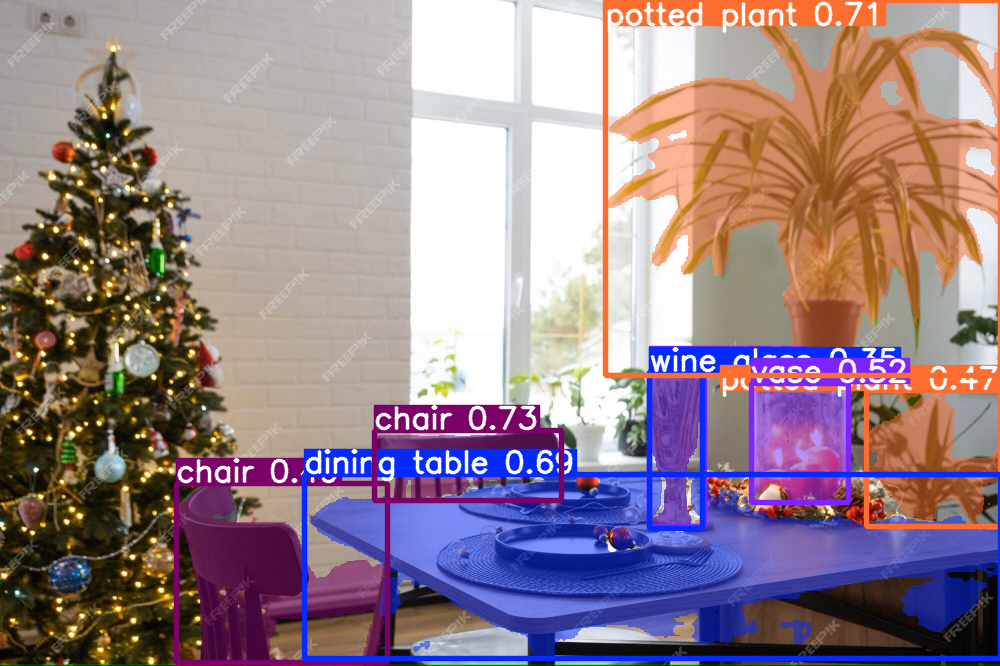

In [13]:
# 5. 예제 이미지 업로드 및 처리
from google.colab import files

uploaded = files.upload()  # 로컬에서 이미지 파일 업로드
for filename in uploaded.keys():
    print(f"Processing {filename}...")
    process_image(filename)

# PyCharm 버전
# process_image("./img/livingroom.jpg")

## **동작 인식 (Pose/Key Point)**

In [14]:
# YOLOv11 모델 파일 다운로드 (예: 구체적인 경로가 필요하다면 대체 가능)
# !wget -O yolo11m-pose.pt https://github.com/ultralytics/assets/releases/download/v8.3.0/yolo11m-pose.pt  # 모델 파일 URL을 기재
!wget -O yolo26n-pose.pt https://platform.ultralytics.com/ultralytics/yolo26/yolo26n-pose  # 모델 파일 URL을 기재

--2026-11-09 14:24:43--  https://platform.ultralytics.com/ultralytics/yolo26/yolo26n-pose
Resolving platform.ultralytics.com (platform.ultralytics.com)... 216.150.16.1, 216.150.1.1
Connecting to platform.ultralytics.com (platform.ultralytics.com)|216.150.16.1|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 513698 (502K) [text/html]
Saving to: ‘yolo26n-pose.pt’

yolo26n-pose.pt     100%[===================>] 501.66K  --.-KB/s    in 0.03s   

2026-11-09 14:24:44 (18.4 MB/s) - ‘yolo26n-pose.pt’ saved [513698/513698]



In [15]:
# 2. 필요한 라이브러리 임포트
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt  # 이미지를 표시할 때 사용
from google.colab.patches import cv2_imshow  # Colab에서 OpenCV 이미지 표시 지원
import os

# 3. YOLOv11 모델 로드
model = YOLO("yolo26n-pose.pt")  # 사전 학습된 COCO 모델 (n: Nano, m: Medium, l: Large 등)

# 4. 이미지 처리 및 결과 표시 함수
def process_image(image_path, conf=0.25, iou=0.45):
    # 이미지 로드
    img = cv2.imread(image_path)

    # YOLO 모델로 추론
    results = model.predict(img, conf=conf, iou=iou)   # conf, iou 임계값 조정 가능
    print(results)

    # 결과를 이미지에 시각화
    annotated_frame = results[0].plot()

    # Colab에서 이미지 표시
    cv2_imshow(annotated_frame)
    # # PyCharm 버전
    # cv2.imshow("YOLO Detection", img)
    # cv2.waitKey(0)
    # cv2.destroyAllWindows()

WARNING ⚠️ Corrupt cache yolo26n-pose.pt, re-downloading yolo26n-pose.pt...


Saving one.png to one.png
Processing one.png...

0: 384x640 1 person, 10.6ms
Speed: 2.3ms preprocess, 10.6ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)
[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
colors: None
depth: None
keypoints: ultralytics.engine.results.Keypoints object
masks: None
names: {0: 'person'}
obb: None
orig_img: array([[[ 70,  60,  53],
        [ 69,  59,  52],
        [ 69,  59,  52],
        ...,
        [ 81,  75,  68],
        [ 84,  78,  71],
        [ 86,  80,  73]],

       [[ 66,  56,  49],
        [ 66,  56,  49],
        [ 66,  56,  49],
        ...,
        [ 82,  76,  69],
        [ 84,  78,  71],
        [ 86,  80,  73]],

       [[ 59,  51,  44],
        [ 60,  52,  45],
        [ 61,  53,  46],
        ...,
        [ 82,  76,  69],
        [ 85,  79,  72],
        [ 87,  81,  74]],

       ...,

       [[ 84,  93, 136],
        [ 84,  93, 136],
        [ 84,  93, 136],
  

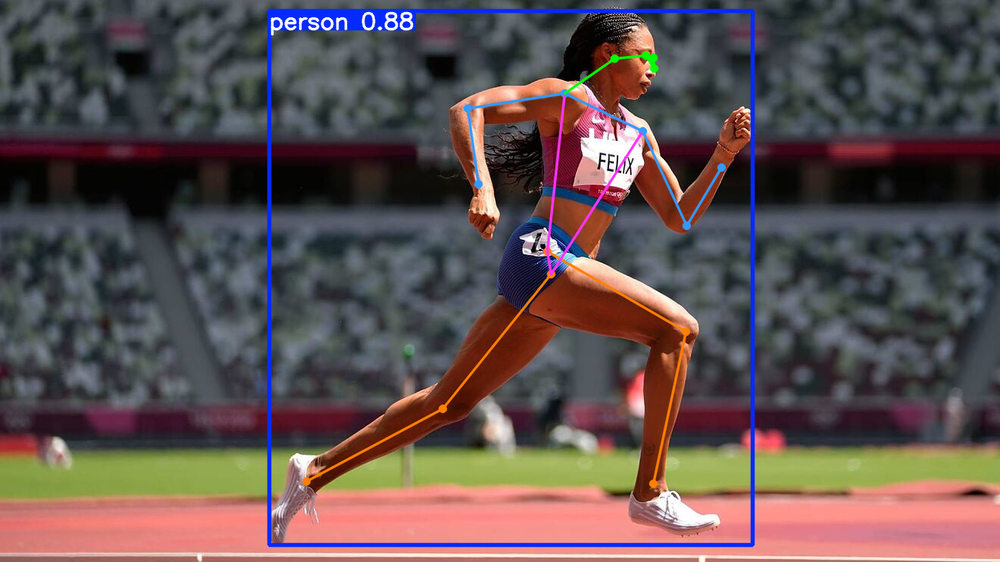

In [16]:
uploaded = files.upload()  # 로컬에서 이미지 파일 업로드
for filename in uploaded.keys():
    print(f"Processing {filename}...")
    process_image(filename)

Saving four.jpg to four.jpg
Processing four.jpg...

0: 448x640 4 persons, 21.2ms
Speed: 1.3ms preprocess, 21.2ms inference, 1.8ms postprocess per image at shape (1, 3, 448, 640)
[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
colors: None
depth: None
keypoints: ultralytics.engine.results.Keypoints object
masks: None
names: {0: 'person'}
obb: None
orig_img: array([[[35, 35, 41],
        [34, 34, 40],
        [34, 34, 40],
        ...,
        [29, 32, 37],
        [29, 31, 39],
        [29, 31, 39]],

       [[35, 35, 41],
        [35, 35, 41],
        [35, 35, 41],
        ...,
        [29, 32, 37],
        [29, 31, 39],
        [29, 31, 39]],

       [[36, 37, 41],
        [35, 36, 40],
        [35, 35, 41],
        ...,
        [31, 31, 37],
        [29, 31, 39],
        [29, 31, 39]],

       ...,

       [[21, 24, 32],
        [21, 24, 32],
        [21, 23, 33],
        ...,
        [24, 27, 41],
        [24, 27, 41],
    

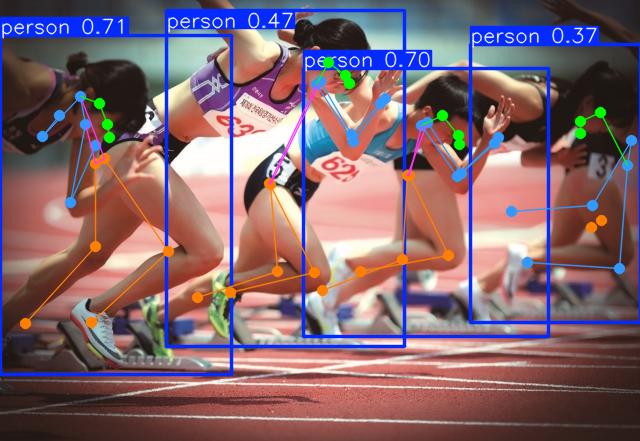

In [17]:
uploaded = files.upload()  # 로컬에서 이미지 파일 업로드
for filename in uploaded.keys():
    print(f"Processing {filename}...")
    process_image(filename)

Saving four.jpg to four (1).jpg
Processing four (1).jpg...

0: 448x640 3 persons, 11.2ms
Speed: 1.2ms preprocess, 11.2ms inference, 1.5ms postprocess per image at shape (1, 3, 448, 640)
[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
colors: None
depth: None
keypoints: ultralytics.engine.results.Keypoints object
masks: None
names: {0: 'person'}
obb: None
orig_img: array([[[35, 35, 41],
        [34, 34, 40],
        [34, 34, 40],
        ...,
        [29, 32, 37],
        [29, 31, 39],
        [29, 31, 39]],

       [[35, 35, 41],
        [35, 35, 41],
        [35, 35, 41],
        ...,
        [29, 32, 37],
        [29, 31, 39],
        [29, 31, 39]],

       [[36, 37, 41],
        [35, 36, 40],
        [35, 35, 41],
        ...,
        [31, 31, 37],
        [29, 31, 39],
        [29, 31, 39]],

       ...,

       [[21, 24, 32],
        [21, 24, 32],
        [21, 23, 33],
        ...,
        [24, 27, 41],
        [24, 27, 4

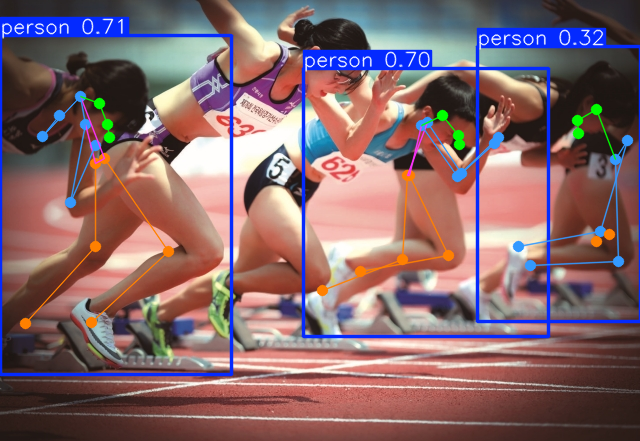

In [18]:
uploaded = files.upload()  # 로컬에서 이미지 파일 업로드
for filename in uploaded.keys():
    print(f"Processing {filename}...")
    process_image(filename, 0.1, 0.2)